# Step 5. EDA & Visualization — Integrated Analysis

## Objective

This notebook examines how multiple flight and weather characteristics are jointly associated with arrival delays at New York City airports in 2013.

We compare arrival delay patterns across combinations of season, scheduled departure time, airline, origin airport, flight distance, and precipitation.

We also examine relationships among continuous predictors and review data completeness before the multivariable statistical analysis in Milestone 4.

All findings are exploratory and do not establish causation or statistical significance.

## 1. Load & Validate Data

Load the cleaned dataset from Step 3 and validate the variables required for integrated analysis.

Use the same cleaned dataset as the previous EDA notebooks to maintain consistency.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

data_path = Path("data/cleaned/analysis_ready_flights.csv")
fig_dir = Path("results/figures")
table_dir = Path("results/tables")

fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

analysis = pd.read_csv(data_path)

required_cols = [
    "arr_delay", "season", "carrier", "origin",
    "scheduled_hour", "distance",
    "precip", "temp", "humid", "wind_speed", "visib"
]

assert all(col in analysis.columns for col in required_cols)
assert analysis["arr_delay"].notna().all()

season_order = ["Winter", "Spring", "Summer", "Fall"]
time_order = ["Overnight", "Morning", "Afternoon", "Evening"]
airport_order = ["EWR", "JFK", "LGA"]

integrated_data = analysis.copy()

assert integrated_data["season"].isin(season_order).all()
assert integrated_data["origin"].isin(airport_order).all()
assert integrated_data["scheduled_hour"].between(0, 23).all()
assert integrated_data["distance"].notna().all()

integrated_data["departure_period"] = pd.cut(
    integrated_data["scheduled_hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=time_order
)

distance_labels = [
    "0-500", "501-1000", "1001-1500",
    "1501-2000", "2001+"
]

integrated_data["distance_group"] = pd.cut(
    integrated_data["distance"],
    bins=[0, 500, 1000, 1500, 2000, np.inf],
    labels=distance_labels
)

assert integrated_data["departure_period"].notna().all()
assert integrated_data["distance_group"].notna().all()

print("Dataset shape:", integrated_data.shape)
print("Total flights:", f"{len(integrated_data):,}")
print("Mean arrival delay:", round(integrated_data["arr_delay"].mean(), 2))

Dataset shape: (327346, 36)
Total flights: 327,346
Mean arrival delay: 6.9


## 2. Season × Scheduled Departure Time

Compare mean arrival delays across seasons and scheduled departure periods.

This analysis explores whether the relationship between scheduled departure time and arrival delay differs across seasons.

Cell sample sizes are examined to avoid overinterpreting groups with very few flights.

In [2]:
season_time_stats = (
    integrated_data
    .groupby(
        ["season", "departure_period"],
        observed=True
    )["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100
    )
)

season_time_mean = (
    season_time_stats["Mean"]
    .unstack("departure_period")
    .reindex(index=season_order, columns=time_order)
)

season_time_counts = (
    season_time_stats["Flights"]
    .unstack("departure_period")
    .reindex(index=season_order, columns=time_order)
)

print("Mean arrival delay:")
display(season_time_mean.round(2))

print("Flight counts:")
display(season_time_counts)

Mean arrival delay:


departure_period,Overnight,Morning,Afternoon,Evening
season,,,,
Winter,0.51,3.19,11.40,15.41
Spring,-4.95,-1.98,10.25,16.17
Summer,-4.46,-1.23,18.46,29.14
Fall,-10.73,-6.72,1.61,3.86


Flight counts:


departure_period,Overnight,Morning,Afternoon,Evening
season,,,,
Winter,487,29747,29926,16869
Spring,462,32054,32272,18806
Summer,537,32691,32541,18355
Fall,454,32154,32278,17713


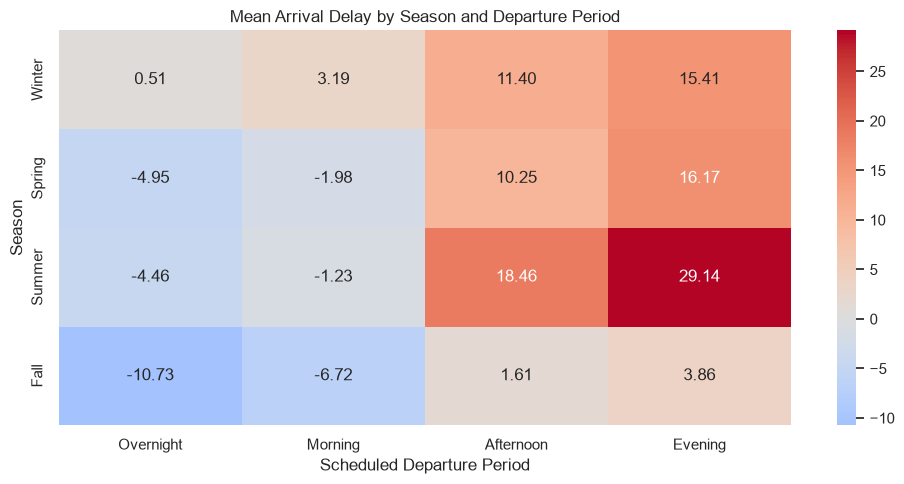

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(
    season_time_mean,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax
)

ax.set(
    title="Mean Arrival Delay by Season and Departure Period",
    xlabel="Scheduled Departure Period",
    ylabel="Season"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "integrated_season_departure_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Origin Airport × Scheduled Departure Time

Compare arrival delay patterns across departure airports and scheduled departure periods.

This analysis explores whether the higher average delays observed during later departure periods are consistent across EWR, JFK, and LGA.

In [4]:
airport_time_stats = (
    integrated_data
    .groupby(
        ["origin", "departure_period"],
        observed=True
    )["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100
    )
)

airport_time_mean = (
    airport_time_stats["Mean"]
    .unstack("departure_period")
    .reindex(index=airport_order, columns=time_order)
)

airport_time_counts = (
    airport_time_stats["Flights"]
    .unstack("departure_period")
    .reindex(index=airport_order, columns=time_order)
)

display(airport_time_mean.round(2))
display(airport_time_counts)

departure_period,Overnight,Morning,Afternoon,Evening
origin,,,,
EWR,-5.75,-1.10,13.49,20.87
JFK,-4.56,-2.11,7.34,13.23
LGA,-2.61,-2.21,10.06,15.18


departure_period,Overnight,Morning,Afternoon,Evening
origin,,,,
EWR,889,45944,46676,23618
JFK,745,37728,41738,28868
LGA,306,42974,38603,19257


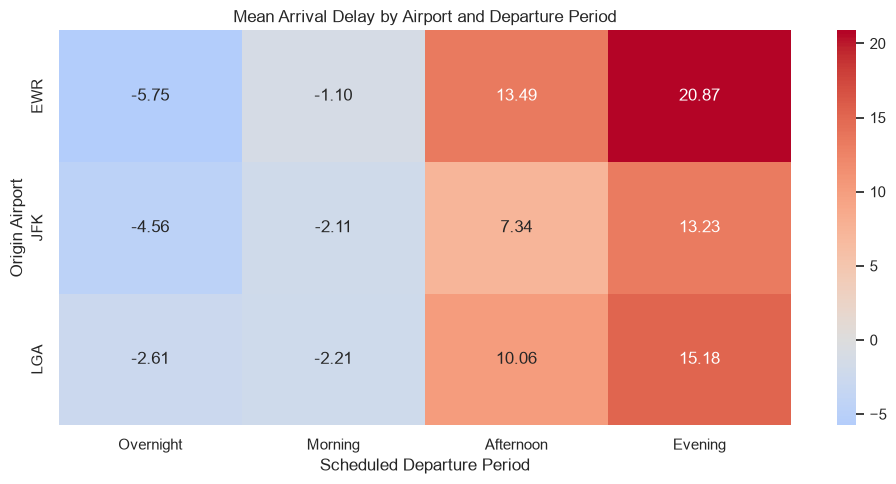

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(
    airport_time_mean,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax
)

ax.set(
    title="Mean Arrival Delay by Airport and Departure Period",
    xlabel="Scheduled Departure Period",
    ylabel="Origin Airport"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "integrated_airport_departure_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Airline × Origin Airport

Compare mean arrival delays across airlines and departure airports.

Some airlines operate relatively few flights at certain airports. Groups with fewer than 100 flights are excluded from the heatmap to reduce the risk of misleading comparisons.

These comparisons remain descriptive and are not adjusted for differences in routes, schedules, or weather.

In [6]:
airline_airport_stats = (
    integrated_data
    .groupby(["carrier", "origin"])["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100
    )
)

airline_airport_mean = (
    airline_airport_stats["Mean"]
    .unstack("origin")
    .reindex(columns=airport_order)
)

airline_airport_counts = (
    airline_airport_stats["Flights"]
    .unstack("origin")
    .reindex(columns=airport_order)
)

airline_airport_plot = airline_airport_mean.where(
    airline_airport_counts >= 100
)

print("Mean arrival delay (groups with n >= 100):")
display(airline_airport_plot.round(2))

print("Flight counts:")
display(airline_airport_counts)

Mean arrival delay (groups with n >= 100):


origin,EWR,JFK,LGA
carrier,,,
9E,1.62,8.84,1.77
AA,0.98,2.08,-1.33
AS,-9.93,NaN,NaN
B6,9.39,8.89,13.51
DL,8.78,-2.38,3.93
EV,17.02,17.79,9.28
F9,NaN,NaN,21.92
FL,NaN,NaN,20.12
HA,NaN,-6.92,NaN


Flight counts:


origin,EWR,JFK,LGA
carrier,,,
9E,1193.0,13742.0,2359.0
AA,3363.0,13600.0,14984.0
AS,709.0,NaN,NaN
B6,6472.0,41666.0,5911.0
DL,4295.0,20559.0,22804.0
EV,41557.0,1326.0,8225.0
F9,NaN,NaN,681.0
FL,NaN,NaN,3175.0
HA,NaN,342.0,NaN


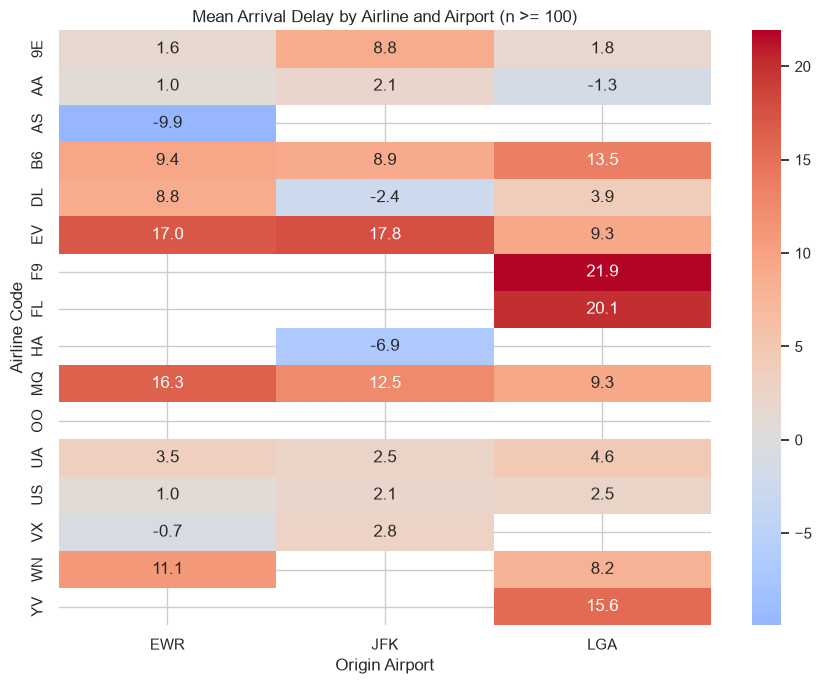

In [7]:
fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    airline_airport_plot,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    center=0,
    mask=airline_airport_plot.isna(),
    ax=ax
)

ax.set(
    title="Mean Arrival Delay by Airline and Airport (n >= 100)",
    xlabel="Origin Airport",
    ylabel="Airline Code"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "integrated_airline_airport_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Season × Precipitation

Compare arrival delays between flights with and without recorded precipitation within each season.

Weather data were matched to flights using the departure airport and hourly timestamp.

Flights with missing precipitation values are excluded from this comparison. The number of observations in each group is reported.

In [8]:
precip_data = integrated_data.loc[
    integrated_data["precip"].notna()
].copy()

precip_data["precip_group"] = np.where(
    precip_data["precip"] > 0,
    "Precipitation",
    "No Precipitation"
)

precip_order = ["No Precipitation", "Precipitation"]

season_precip_stats = (
    precip_data
    .groupby(["season", "precip_group"])["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100
    )
)

season_precip_mean = (
    season_precip_stats["Mean"]
    .unstack("precip_group")
    .reindex(index=season_order, columns=precip_order)
)

season_precip_counts = (
    season_precip_stats["Flights"]
    .unstack("precip_group")
    .reindex(index=season_order, columns=precip_order)
)

display(season_precip_mean.round(2))
display(season_precip_counts)

precip_group,No Precipitation,Precipitation
season,,
Winter,7.28,27.67
Spring,4.95,30.52
Summer,10.39,48.84
Fall,-2.03,22.24


precip_group,No Precipitation,Precipitation
season,,
Winter,69418,6617
Spring,77500,6078
Summer,78231,5649
Fall,79728,2598


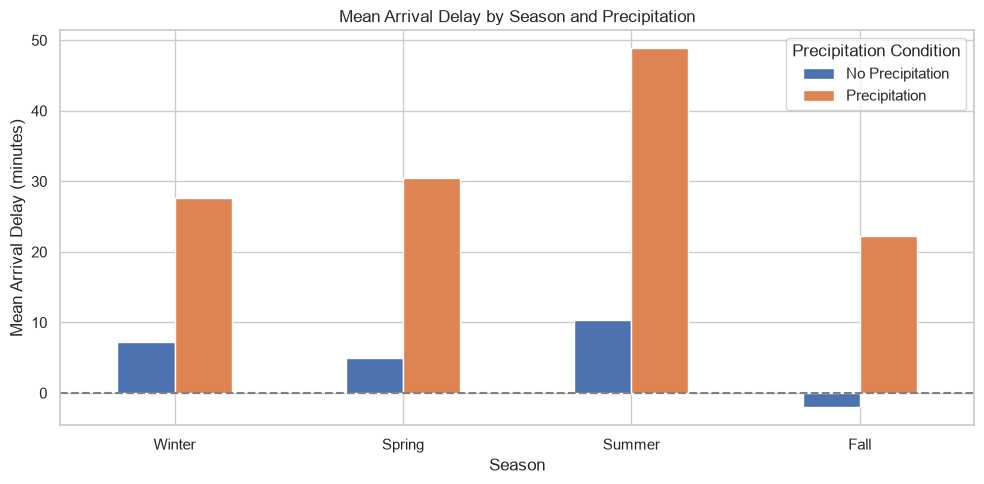

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

season_precip_mean.plot(
    kind="bar",
    ax=ax
)

ax.set(
    title="Mean Arrival Delay by Season and Precipitation",
    xlabel="Season",
    ylabel="Mean Arrival Delay (minutes)"
)

ax.axhline(0, color="gray", linestyle="--")
ax.legend(title="Precipitation Condition")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    fig_dir / "integrated_season_precipitation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Flight Distance × Scheduled Departure Time

Compare mean arrival delays across flight distance groups and scheduled departure periods.

This analysis explores whether the relationship between flight distance and arrival delay differs by scheduled departure time.

Groups with fewer than 100 flights are not displayed in the heatmap, but their observations remain in the dataset.

In [10]:
distance_time_stats = (
    integrated_data
    .groupby(
        ["distance_group", "departure_period"],
        observed=True
    )["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100
    )
)

distance_time_mean = (
    distance_time_stats["Mean"]
    .unstack("departure_period")
    .reindex(index=distance_labels, columns=time_order)
)

distance_time_counts = (
    distance_time_stats["Flights"]
    .unstack("departure_period")
    .reindex(index=distance_labels, columns=time_order)
)

distance_time_plot = distance_time_mean.where(
    distance_time_counts >= 100
)

display(distance_time_plot.round(2))
display(distance_time_counts)

departure_period,Overnight,Morning,Afternoon,Evening
distance_group,,,,
0-500,NaN,0.83,11.58,16.63
501-1000,-5.50,-0.39,13.55,19.85
1001-1500,-7.32,-2.24,8.69,17.59
1501-2000,-0.51,-3.42,9.42,12.91
2001+,NaN,-6.80,4.45,9.58


departure_period,Overnight,Morning,Afternoon,Evening
distance_group,,,,
0-500,31,26000,30628,20116
501-1000,375,42427,42781,20236
1001-1500,1058,30445,27132,14163
1501-2000,405,7956,7343,5068
2001+,71,19818,19133,12160


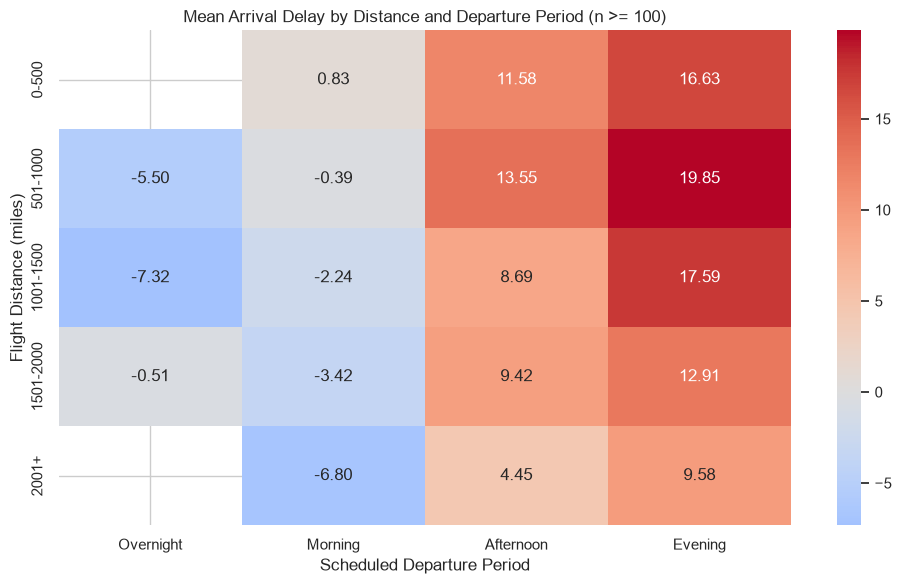

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    distance_time_plot,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    mask=distance_time_plot.isna(),
    ax=ax
)

ax.set(
    title="Mean Arrival Delay by Distance and Departure Period (n >= 100)",
    xlabel="Scheduled Departure Period",
    ylabel="Flight Distance (miles)"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "integrated_distance_departure_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Continuous Variable Correlations

Examine Pearson correlations among arrival delay, scheduled departure hour, flight distance, and continuous weather variables.

This analysis helps identify potential relationships among predictors before fitting multivariable regression models.

Pairwise correlations do not establish multicollinearity or statistical significance. Additional diagnostics will be conducted in Milestone 4.

In [12]:
continuous_vars = [
    "arr_delay",
    "scheduled_hour",
    "distance",
    "temp",
    "humid",
    "wind_speed",
    "precip",
    "visib"
]

correlation_matrix = (
    integrated_data[continuous_vars]
    .corr(method="pearson")
)

display(correlation_matrix.round(3))

,arr_delay,scheduled_hour,distance,temp,humid,wind_speed,precip,visib
arr_delay,1.000,0.173,-0.062,0.033,0.141,0.064,0.111,-0.136
scheduled_hour,0.173,1.000,-0.014,0.080,-0.166,0.121,0.006,0.073
distance,-0.062,-0.014,1.000,0.011,0.043,0.018,0.002,-0.013
temp,0.033,0.080,0.011,1.000,0.042,-0.142,0.009,0.091
humid,0.141,-0.166,0.043,0.042,1.000,-0.204,0.233,-0.544
wind_speed,0.064,0.121,0.018,-0.142,-0.204,1.000,0.033,0.072
precip,0.111,0.006,0.002,0.009,0.233,0.033,1.000,-0.320
visib,-0.136,0.073,-0.013,0.091,-0.544,0.072,-0.320,1.000


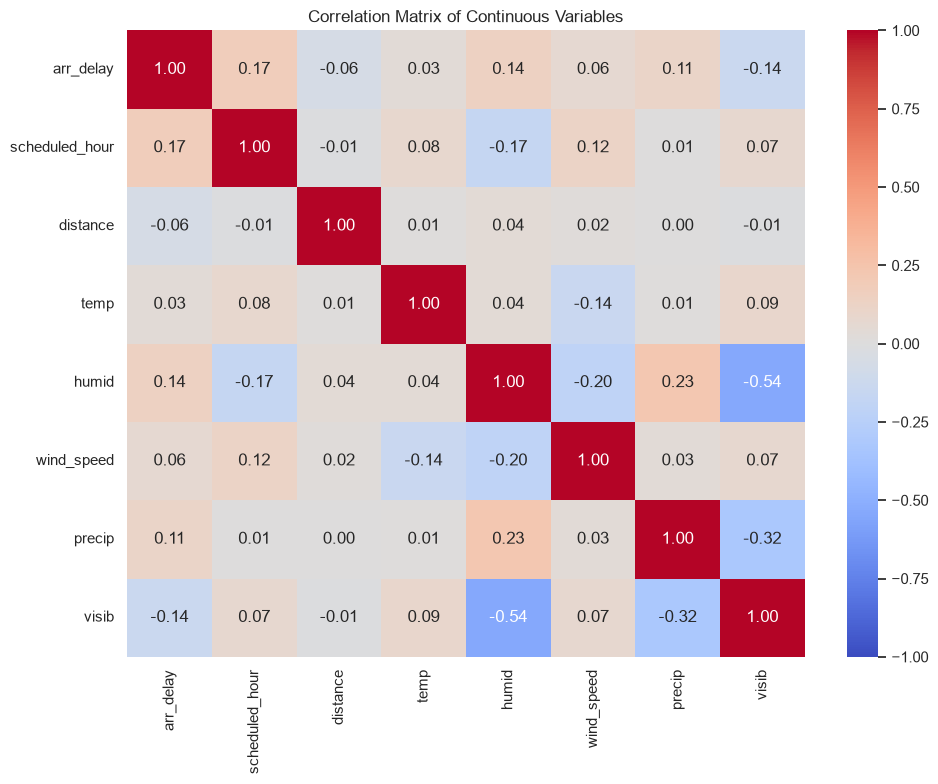

In [13]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title("Correlation Matrix of Continuous Variables")

plt.tight_layout()

plt.savefig(
    fig_dir / "integrated_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Data Completeness for Multivariable Analysis

Review the completeness of variables that may be used in the next statistical analysis.

Compare the available sample size for a model using flight characteristics with a model that also includes weather variables.

This step does not fit a regression model. It only checks how missing values may affect the analysis sample.

In [14]:
flight_model_vars = [
    "arr_delay",
    "season",
    "carrier",
    "origin",
    "scheduled_hour",
    "distance"
]

weather_model_vars = flight_model_vars + [
    "temp",
    "humid",
    "wind_speed",
    "precip",
    "visib"
]

flight_model_n = (
    integrated_data[flight_model_vars]
    .dropna()
    .shape[0]
)

weather_model_n = (
    integrated_data[weather_model_vars]
    .dropna()
    .shape[0]
)

model_sample_stats = pd.DataFrame({
    "Model_Dataset": [
        "All Cleaned Flights",
        "Flight Characteristics Only",
        "Flight + Weather Characteristics"
    ],
    "Flights": [
        len(integrated_data),
        flight_model_n,
        weather_model_n
    ]
})

model_sample_stats["Share_of_Total_Pct"] = (
    model_sample_stats["Flights"]
    / len(integrated_data)
    * 100
)

display(model_sample_stats.round(2))

print("\nMissing values by variable:")
display(
    integrated_data[weather_model_vars]
    .isna()
    .sum()
    .to_frame("Missing_Count")
)

,Model_Dataset,Flights,Share_of_Total_Pct
0,All Cleaned Flights,327346,100.0
1,Flight Characteristics Only,327346,100.0
2,Flight + Weather Characteristics,325724,99.5



Missing values by variable:


,Missing_Count
arr_delay,0
season,0
carrier,0
origin,0
scheduled_hour,0
distance,0
temp,1544
humid,1544
wind_speed,1605
precip,1527


## 9. Save Results

Export cross-variable descriptive statistics, correlation results, and model sample-size comparisons.

These results will support the final report and the statistical analysis in Milestone 4.

In [15]:
tables = {
    "integrated_season_departure": season_time_stats,
    "integrated_airport_departure": airport_time_stats,
    "integrated_airline_airport": airline_airport_stats,
    "integrated_season_precipitation": season_precip_stats,
    "integrated_distance_departure": distance_time_stats,
    "integrated_correlations": correlation_matrix,
    "integrated_model_sample_sizes": model_sample_stats
}

for name, table in tables.items():
    table.to_csv(table_dir / f"{name}.csv")

print(f"Saved {len(tables)} integrated analysis tables.")

Saved 7 integrated analysis tables.


In [16]:
print("=== INTEGRATED EDA SUMMARY ===")

print("\n1. Season × Departure Time:")
display(season_time_mean.round(2))
print("Sample sizes:")
display(season_time_counts)

print("\n2. Airport × Departure Time:")
display(airport_time_mean.round(2))
print("Sample sizes:")
display(airport_time_counts)

print("\n3. Airline × Airport (n >= 100):")
display(airline_airport_plot.round(2))

print("\n4. Season × Precipitation:")
display(season_precip_mean.round(2))
print("Sample sizes:")
display(season_precip_counts)

print("\n5. Distance × Departure Time (n >= 100):")
display(distance_time_plot.round(2))

print("\n6. Correlations with Arrival Delay:")
display(
    correlation_matrix["arr_delay"]
    .sort_values(ascending=False)
    .round(4)
)

print("\n7. Multivariable Model Sample Sizes:")
display(model_sample_stats.round(2))

=== INTEGRATED EDA SUMMARY ===

1. Season × Departure Time:


departure_period,Overnight,Morning,Afternoon,Evening
season,,,,
Winter,0.51,3.19,11.40,15.41
Spring,-4.95,-1.98,10.25,16.17
Summer,-4.46,-1.23,18.46,29.14
Fall,-10.73,-6.72,1.61,3.86


Sample sizes:


departure_period,Overnight,Morning,Afternoon,Evening
season,,,,
Winter,487,29747,29926,16869
Spring,462,32054,32272,18806
Summer,537,32691,32541,18355
Fall,454,32154,32278,17713



2. Airport × Departure Time:


departure_period,Overnight,Morning,Afternoon,Evening
origin,,,,
EWR,-5.75,-1.10,13.49,20.87
JFK,-4.56,-2.11,7.34,13.23
LGA,-2.61,-2.21,10.06,15.18


... (10 outputs left out)


6. Correlations with Arrival Delay:


arr_delay         1.0000
scheduled_hour    0.1735
humid             0.1414
precip            0.1113
wind_speed        0.0641
temp              0.0330
distance         -0.0619
visib            -0.1355
Name: arr_delay, dtype: float64


7. Multivariable Model Sample Sizes:


,Model_Dataset,Flights,Share_of_Total_Pct
0,All Cleaned Flights,327346,100.0
1,Flight Characteristics Only,327346,100.0
2,Flight + Weather Characteristics,325724,99.5



## 10. Key Findings and Limitations

### Key Findings

The integrated analysis showed that arrival delay patterns varied across combinations of flight and weather characteristics.

Mean arrival delays generally increased from morning to evening across all seasons. Summer evening flights had the highest mean delay among the season and departure period combinations (29.14 minutes), compared with −1.23 minutes for summer morning flights.

Evening flights also had higher mean delays than morning flights at all three airports. EWR had the highest evening mean delay (20.87 minutes), followed by LGA (15.18 minutes) and JFK (13.23 minutes).

The airline and airport comparison showed that mean arrival delays differed across airlines and departure airports. For example, Delta Air Lines (DL) had a mean delay of 8.78 minutes at EWR, −2.38 minutes at JFK, and 3.93 minutes at LGA. These differences may reflect variations in routes, schedules, or operating conditions.

Flights with recorded precipitation had higher mean arrival delays than flights without precipitation in every season. The largest difference was observed in Summer, with a mean delay of 48.84 minutes during precipitation compared with 10.39 minutes without precipitation.

The distance and departure time comparison showed that evening flights had higher mean delays than morning flights across all five distance groups. This suggests that scheduled departure time may be an important factor to consider alongside flight distance.

Pearson correlations with arrival delay were relatively weak. Scheduled departure hour had the largest absolute correlation among the continuous predictors examined (r = 0.1735), followed by humidity (r = 0.1414), visibility (r = −0.1355), and precipitation (r = 0.1113).

The data completeness analysis showed that all 327,346 cleaned flights were available for a model using flight characteristics only. Including the selected weather variables reduced the complete-case sample to 325,724 flights (99.50%).

Overall, the findings suggest that season, scheduled departure time, airline, airport, flight distance, and weather conditions should be examined together in the next statistical analysis.

### Limitations

This analysis only includes flights departing from New York City airports in 2013, so the findings may not represent current flight operations.

Some combinations of variables contained relatively few flights. These groups may produce less stable descriptive statistics, particularly for overnight departures and airline-airport combinations with limited observations.

The cross-variable comparisons did not fully control for other factors. For example, differences between airlines or airports may reflect differences in destinations, schedules, or weather conditions.

The observed patterns do not establish causal relationships or statistical significance. Additional statistical modeling is needed to evaluate associations while accounting for multiple variables.

Pearson correlations only measure linear relationships between pairs of variables. They do not capture all possible relationships or determine whether a multivariable regression model satisfies its assumptions.

Missing weather observations may reduce the sample size used in regression models. In addition, multiple flights can share the same hourly weather observation, which should be considered when evaluating statistical uncertainty.

### Data Preparation and Quality Notes

This analysis uses the cleaned flight dataset prepared in Step 3, containing 327,346 flights.

Flights with missing arrival delay values were excluded during data cleaning.

Scheduled departure times were grouped into Overnight, Morning, Afternoon, and Evening periods. Flight distances were grouped into the same five categories used in the previous distance analysis.

Weather observations were matched to flights using the departure airport and hourly timestamp during Step 3. Flights with missing precipitation values were excluded only from comparisons requiring that variable.

Groups with fewer than 100 flights were hidden in selected airline-airport and distance-departure heatmaps to avoid overinterpreting small samples. The original cleaned dataset was not modified.

The correlation matrix was calculated using available observations for each variable pair. The model sample-size comparison used complete cases for the selected flight and weather variables.

All results in this notebook are descriptive. Multivariable regression, model diagnostics, and statistical inference will be conducted in Milestone 4.
